# 3 · Desacople PIB–CO2 por país

**Pregunta:** entre 2000 y 2024, ¿qué países crecieron sin aumentar sus emisiones?

**Clasificación (OCDE):**

| Categoría | Condición |
|---|---|
| Absoluto | PIB ↑ y CO2 ↓ |
| Relativo | PIB ↑, CO2 ↑ pero más lento que el PIB |
| Sin desacople | CO2 crece igual o más rápido que el PIB |
| Recesión | el PIB no creció: bajar emisiones así no es desacople |

**Decisiones de método:**
* PIB real en PPA (USD internacionales constantes de 2021) del Banco Mundial; CO2 fósil + industria (territorial) de OWID.
* Los extremos son **promedios de 3 años** (2000–2002 y 2022–2024): un año de sequía, crisis o pandemia no decide la etiqueta.
* Además de la etiqueta OCDE uso la **elasticidad de Tapio** (%ΔCO2 / %ΔPIB), con su banda de "acoplamiento" 0,8–1,2.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from desarrollo_co2 import config, descarga, limpieza, union, desacople as D, kaya, kuznets as K, graficos
from desarrollo_co2.graficos import num   # formato español: 1.234,56

pd.set_option("display.float_format", lambda v: num(v, 2))
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

In [2]:
panel = pd.read_csv(config.PANEL)
ini, fin = config.PERIODO_DESACOPLE
tabla = D.tabla_desacople(panel, ini, fin)
tabla[["pais", "crec_pib_anual", "crec_co2_anual", "cambio_intensidad_pct", "elasticidad", "categoria", "tapio"]]

,pais,crec_pib_anual,crec_co2_anual,cambio_intensidad_pct,elasticidad,categoria,tapio
0,México,"1,55","0,58","-19,05","0,37",Relativo,Desacople débil
1,Argentina,"2,16","1,28","-17,41","0,59",Relativo,Desacople débil
2,América Latina (18),"2,45","1,47","-19,11","0,60",Relativo,Desacople débil
3,Nicaragua,"3,29","1,53","-31,48","0,46",Relativo,Desacople débil
4,Brasil,"2,22","1,54","-13,77","0,69",Relativo,Desacople débil
5,Chile,"3,41","1,72","-30,32","0,51",Relativo,Desacople débil
6,El Salvador,"2,11","1,73","-7,84","0,82",Relativo,Acoplamiento expansivo
7,Costa Rica,"3,96","1,75","-37,67","0,44",Relativo,Desacople débil
8,Uruguay,"2,78","2,02","-15,08","0,73",Relativo,Desacople débil
9,Colombia,"3,73","2,21","-27,72","0,59",Relativo,Desacople débil


In [3]:
D.conteo_categorias(tabla)

categoria
Absoluto          0
Relativo         14
Sin desacople     4
Recesión          0
Sin datos         2
Name: count, dtype: int64

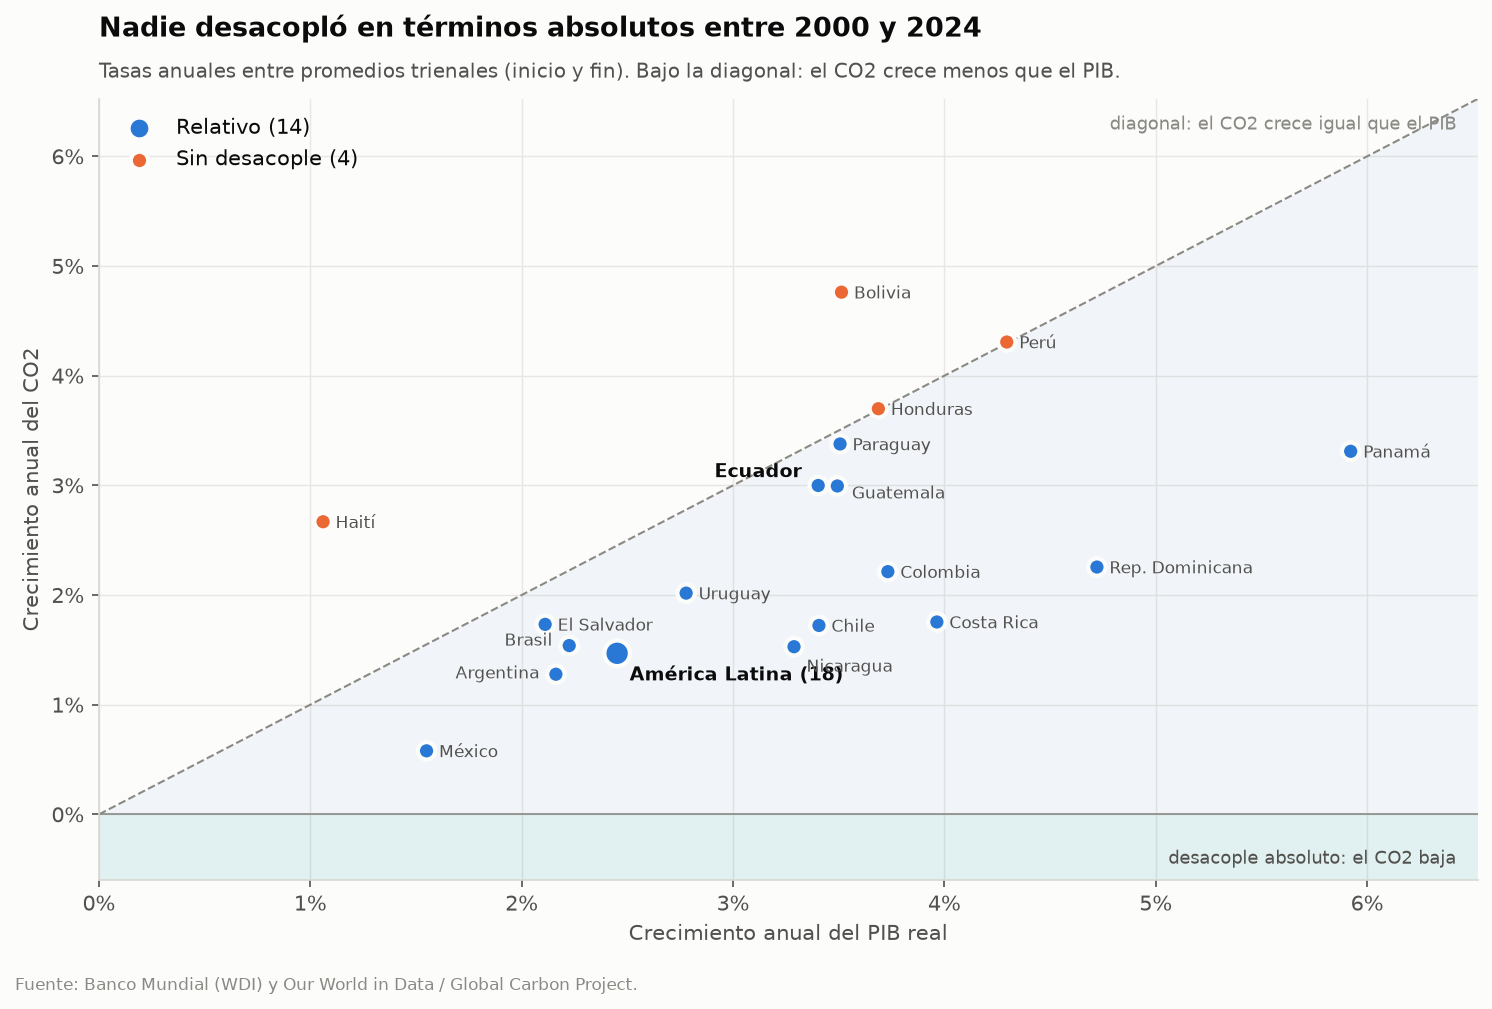

In [4]:
display(Image(config.FIGURAS / "04_desacople_paises.png"))

**Resultado principal:** ningún país de los 18 con datos logró desacople absoluto en 2000–2024. 14 lograron desacople relativo (el CO2 creció, pero menos que la economía) y 4 no desacoplaron (Bolivia, Perú, Honduras y Haití).

La región como agregado creció 2,5 % al año y su CO2 1,5 %: elasticidad 0,60.

## 3.1 La etiqueta OCDE vs Tapio: los casos al límite

In [5]:
pd.crosstab(tabla["categoria"].astype(str), tabla["tapio"])

tapio,Acoplamiento expansivo,Desacople débil,Desacople negativo expansivo,Sin datos
categoria,,,,
Relativo,4,11,0,0
Sin datos,0,0,0,2
Sin desacople,2,0,2,0


In [6]:
tabla[tabla["elasticidad"].between(0.8, 1.2)][["pais", "elasticidad", "categoria", "tapio"]]

,pais,elasticidad,categoria,tapio
6,El Salvador,"0,82",Relativo,Acoplamiento expansivo
11,Guatemala,"0,86",Relativo,Acoplamiento expansivo
12,Ecuador,"0,88",Relativo,Acoplamiento expansivo
14,Paraguay,"0,96",Relativo,Acoplamiento expansivo
16,Honduras,"1,00",Sin desacople,Acoplamiento expansivo
17,Perú,"1,00",Sin desacople,Acoplamiento expansivo


Paraguay (0,96), Ecuador (0,88), Guatemala (0,86) y El Salvador (0,82) salen como "Relativo" con la regla OCDE, pero su CO2 creció casi al mismo ritmo que el PIB. Con Tapio están **acoplados**. Con la regla binaria, una décima de punto cambia la etiqueta; por eso reporto las dos.

## 3.2 Subperiodos: auge de materias primas (2000–2012) y después (2012–2024)

In [7]:
subs = {f"{a}–{b}": D.tabla_desacople(panel, a, b) for a, b in config.SUBPERIODOS}
pd.DataFrame({k: D.conteo_categorias(t) for k, t in subs.items()})

,2000–2012,2012–2024
categoria,,
Absoluto,0,3
Relativo,12,9
Sin desacople,6,5
Recesión,0,1
Sin datos,2,2


In [8]:
t2 = subs["2012–2024"]
t2[t2["categoria"].isin(["Absoluto", "Recesión"])][["pais", "crec_pib_anual", "crec_co2_anual", "categoria"]]

,pais,crec_pib_anual,crec_co2_anual,categoria
0,Brasil,"0,63","-0,91",Absoluto
1,México,"1,31","-0,75",Absoluto
2,Argentina,"0,15","-0,66",Absoluto
3,América Latina (18),"1,34","-0,16",Absoluto
18,Haití,"-0,07","1,28",Recesión


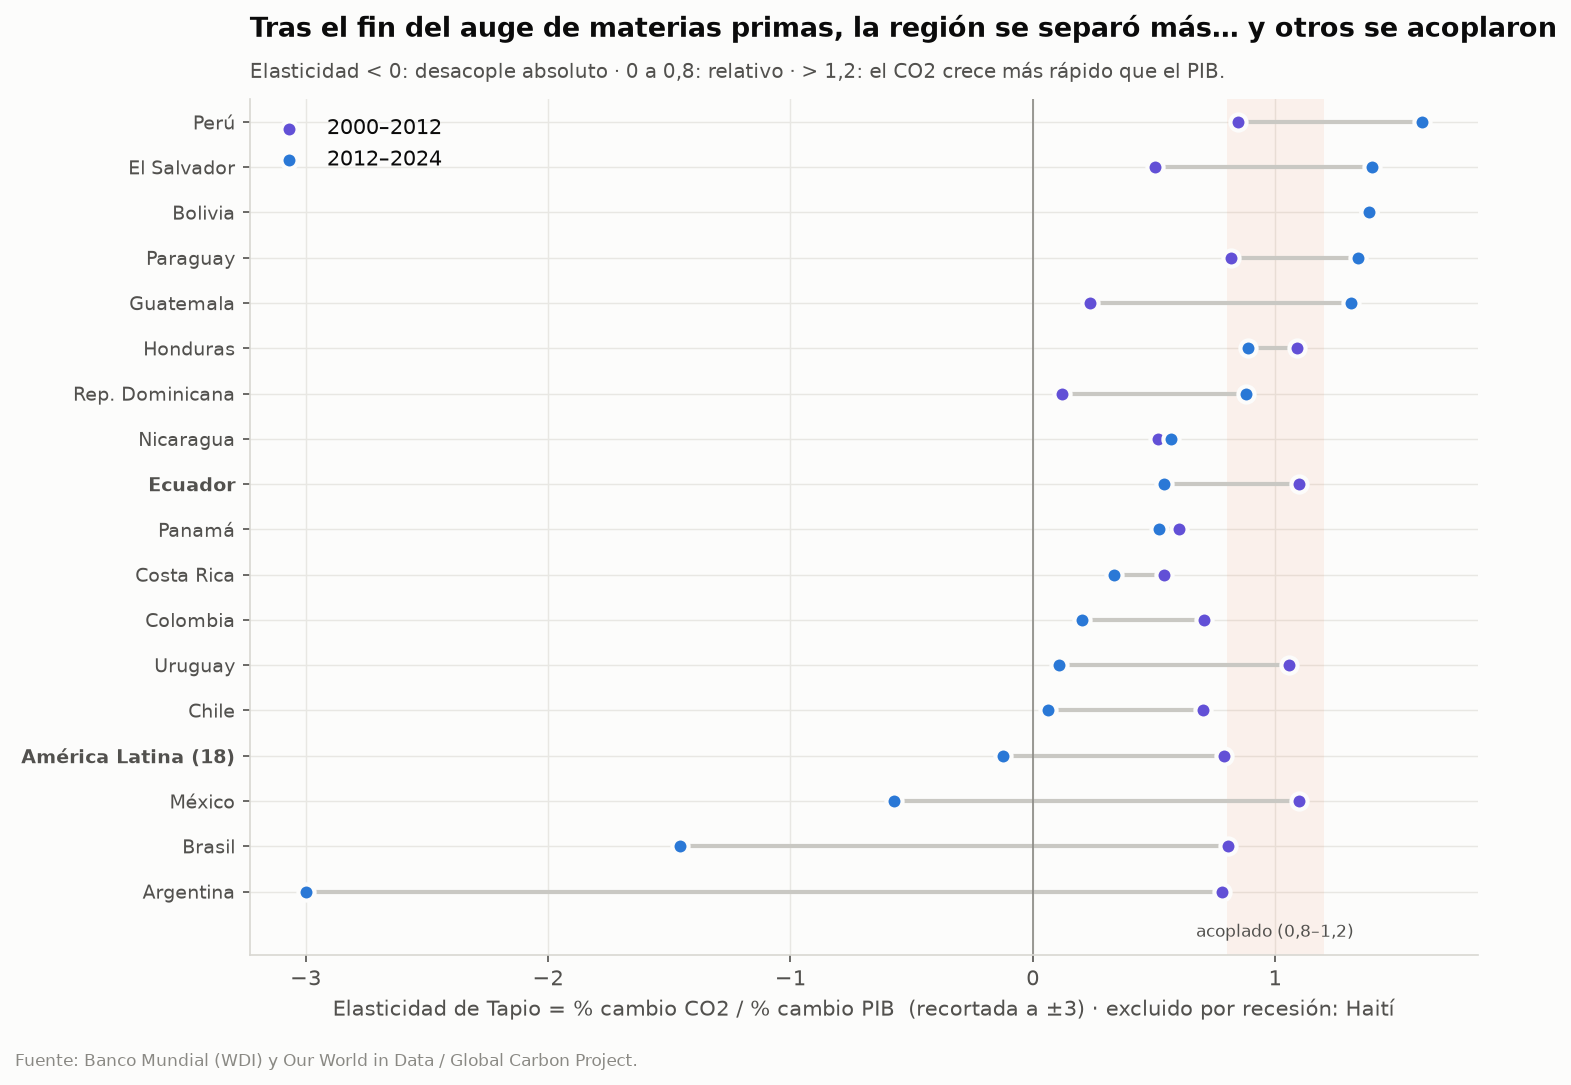

In [9]:
display(Image(config.FIGURAS / "05_desacople_subperiodos.png"))

Los tres desacoples absolutos de 2012–2024 (**Brasil, México y Argentina**) se dieron con economías que crecieron poco (0,2 % a 1,3 % al año). Es real (el CO2 bajó mientras el PIB subía) pero no es el "crecimiento verde" de los países que crecen rápido: con poco crecimiento, cualquier mejora de eficiencia o un cambio de mezcla eléctrica basta para que el CO2 caiga. Haití queda en recesión y se excluye del gráfico de elasticidades. En cambio, Guatemala, Paraguay, Perú, Bolivia y El Salvador **se acoplaron más** en el segundo periodo: su CO2 creció más rápido que su PIB.

## 3.3 Ventanas móviles de 10 años

In [10]:
movil = D.desacople_movil(panel)
movil.groupby(["fin", "categoria"], observed=True).size().unstack(fill_value=0).tail(8)

categoria,Absoluto,Recesión,Relativo,Sin datos,Sin desacople
fin,,,,,
2017,2,0,11,2,5
2018,3,0,9,2,6
2019,2,0,10,2,6
2020,5,1,9,2,3
2021,2,1,8,2,7
2022,4,0,9,2,5
2023,3,2,8,2,5
2024,3,1,8,2,6


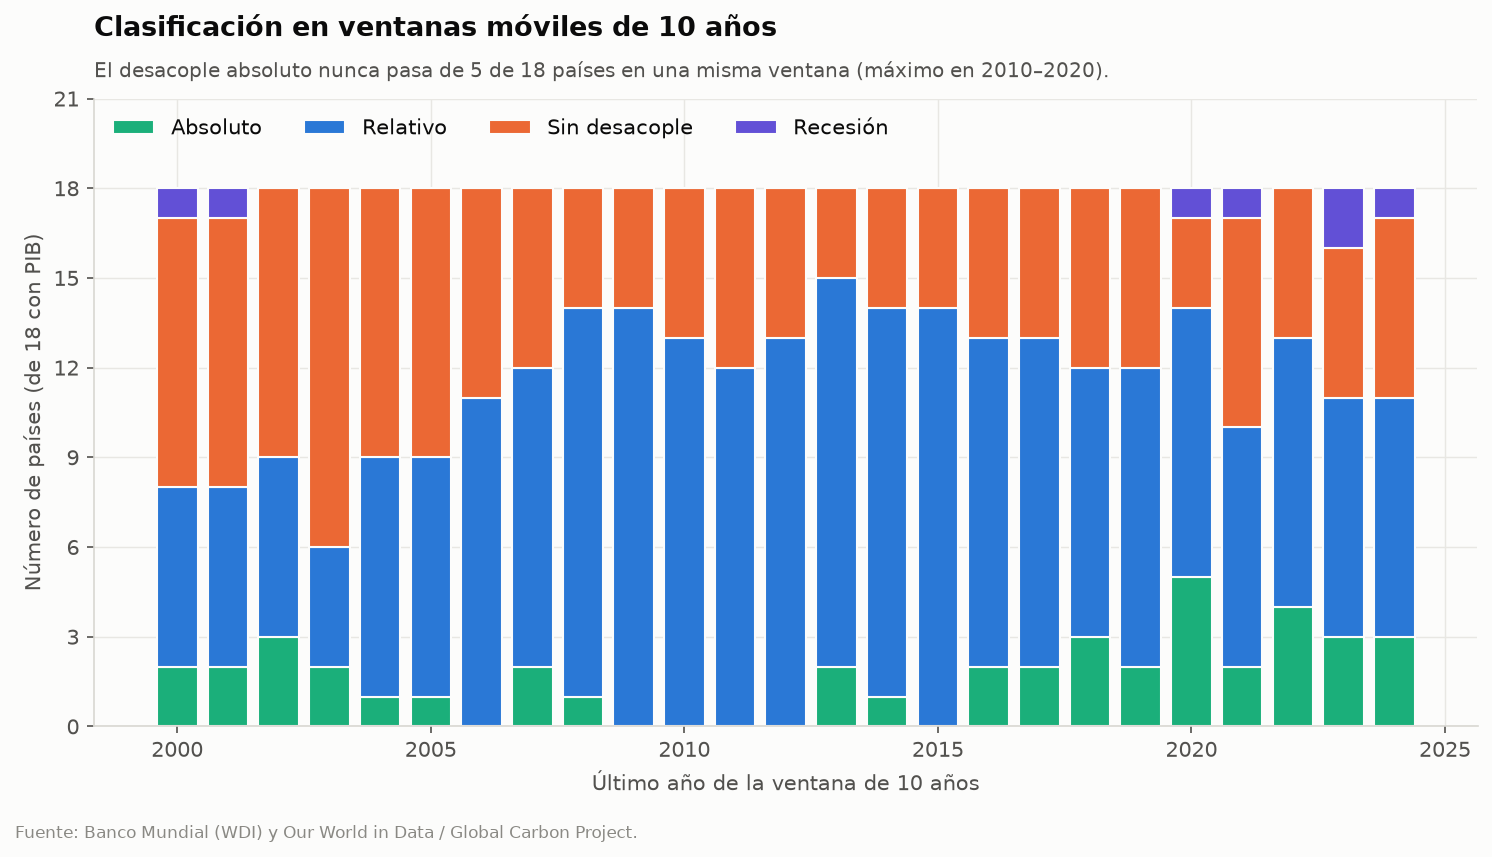

In [11]:
display(Image(config.FIGURAS / "06_desacople_movil.png"))

Ninguna ventana de 10 años tuvo más de 5 de 18 países en desacople absoluto, y la de 2020 está inflada porque termina en el año de la pandemia. El patrón dominante en toda la serie es el desacople **relativo**.

## 3.4 Robustez: ¿cambia la conclusión con otra medida de CO2?

* **Consumo**: asigna al país las emisiones de lo que consume, incluidas las importadas (2000–2023; sin Cuba ni Haití).
* **Con uso del suelo**: suma la deforestación.

In [12]:
rob = D.comparar_medidas(panel, *config.PERIODO_CONSUMO)
rob

,iso3,pais,Territorial,Consumo,Con uso de suelo
0,ARG,Argentina,Relativo,Relativo,Relativo
1,BOL,Bolivia,Sin desacople,Sin desacople,Relativo
2,BRA,Brasil,Relativo,Relativo,Absoluto
3,CHL,Chile,Relativo,Relativo,Relativo
4,COL,Colombia,Relativo,Relativo,Relativo
5,CRI,Costa Rica,Relativo,Relativo,Absoluto
6,CUB,Cuba,Sin datos,Sin datos,Sin datos
7,DOM,Rep. Dominicana,Relativo,Relativo,Relativo
8,ECU,Ecuador,Relativo,Sin desacople,Relativo
9,GTM,Guatemala,Relativo,Relativo,Absoluto


In [13]:
pd.DataFrame({c: rob[rob["iso3"] != config.REGION][c].value_counts() for c in ["Territorial", "Consumo", "Con uso de suelo"]}).fillna(0).astype(int)

,Territorial,Consumo,Con uso de suelo
Absoluto,0,0,10
Relativo,15,11,7
Sin desacople,3,6,1
Recesión,0,0,0
Sin datos,2,3,2


* La columna territorial usa aquí 2000–2023 (para comparar con consumo) y ya cambia un caso: Paraguay pasa a "sin desacople" con un año menos. Otra señal de lo frágiles que son las etiquetas cerca de la diagonal.
* **Con CO2 de consumo el panorama empeora**: Ecuador, Honduras, Panamá y Perú pasan a "sin desacople" (Bolivia y Paraguay ya lo estaban). Parte del desacople territorial se explica porque esos países importan cada vez más bienes cuya fabricación emitió CO2 en otro lugar.
* **Con uso del suelo** aparecen muchos desacoples absolutos (Brasil, México, Costa Rica, Perú…) porque la deforestación de 2000–2002 era muy alta. Es una buena noticia, pero depende de estimaciones con mucha incertidumbre.
* La conclusión robusta es: **en energía y en industria, la región desacopla en términos relativos, no absolutos**.